# Chapitre 17 - Exercices 17.7 à 17.12

Exercices de programmation sur le modèle graphique gaussien (17.7 : algorithme 17.1,
17.8 : lasso et graphical lasso, 17.9 : algorithme EM avec valeurs manquantes), puis
exercices sur le modèle de Ising (17.10 : nœud constant, 17.11 : lois conditionnelles
logistiques, 17.12 : lien avec la régression de Poisson).

**Données.** Les exercices 17.7–17.9 utilisent les données de cytométrie en flux de
Sachs et al. (11 protéines, 7466 cellules), qui ne sont pas disponibles ici. Nous les
remplaçons par des données gaussiennes **simulées** de même taille dont le vrai graphe
est celui de la figure 17.1 (`g.simulate_cytometry_like`). Les noms de protéines ne
sont que des étiquettes. Avantage : on connaît la vérité et on peut juger les
estimations.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

In [2]:
Xc, Theta_vrai, A_fig = g.simulate_cytometry_like(N=7466, seed=0)
noms, _, pos = g.cytometry_like_graph()
N, p = Xc.shape
Sc = g.empirical_covariance(Xc)
print("N = %d, p = %d, arêtes du graphe de la figure 17.1 : %d" % (N, p, A_fig.sum() // 2))

N = 7466, p = 11, arêtes du graphe de la figure 17.1 : 16


## Exercice 17.7 : Programmer l'algorithme 17.1

**Énoncé.** Écrire un programme mettant en œuvre la procédure de régressions modifiées
(algorithme 17.1) pour ajuster un modèle graphique gaussien dont certaines arêtes sont
imposées absentes. L'essayer sur les données de cytométrie avec le graphe de la
figure 17.1.

**Rappels.** On maximise $\log\det\Theta - \operatorname{tr}(S\Theta)$ sous $\theta_{jk} = 0$ pour
$(j,k)\notin E$. Pour chaque variable $j$, on résout le système réduit aux voisins
$W^*_{11}\beta^* = s^*_{12}$ (éq. (17.19)), on complète $\beta$ par des zéros et on met à jour
$w_{12} = W_{11}\hat\beta$ ; à la fin, $\hat\theta_{22} = 1/(s_{22} - w_{12}^T\hat\beta)$ et
$\hat\theta_{12} = -\hat\beta\,\hat\theta_{22}$ (exercice 17.6).

In [3]:
def algorithme_17_1(S, A, tol=1e-10, max_cycles=1000):
    """Version commentée de l'algorithme 17.1 (régressions modifiées)."""
    p = S.shape[0]
    W = S.copy()                                   # étape 1
    betas = np.zeros((p, p))                       # betas[:, j] : régression de j
    for cycle in range(max_cycles):                # étape 2
        W_avant = W.copy()
        for j in range(p):
            autres = np.array([k for k in range(p) if k != j])
            vois = autres[A[j, autres]]            # variables reliées à j
            beta = np.zeros(p)
            if len(vois) > 0:                      # (b) système réduit (17.19)
                beta[vois] = np.linalg.solve(W[np.ix_(vois, vois)], S[vois, j])
            betas[:, j] = beta
            w12 = W[np.ix_(autres, autres)] @ beta[autres]   # (c)
            W[autres, j] = w12
            W[j, autres] = w12
        if np.abs(W - W_avant).max() < tol:
            break
    Theta = np.zeros((p, p))                       # étape 3
    for j in range(p):
        autres = [k for k in range(p) if k != j]
        t22 = 1.0 / (S[j, j] - W[autres, j] @ betas[autres, j])
        Theta[j, j] = t22
        Theta[autres, j] = -betas[autres, j] * t22
    return W, (Theta + Theta.T) / 2, cycle + 1


W17, T17, n_cycles = algorithme_17_1(Sc, A_fig)
W_mod, T_mod = g.fit_known_graph(Sc, A_fig)
print("convergence en %d cycles ; écart avec esl.ch17_graphes : %.1e" % (n_cycles, np.abs(T17 - T_mod).max()))

convergence en 3 cycles ; écart avec esl.ch17_graphes : 0.0e+00


**Vérifications des propriétés de la solution.**

1. $\hat\theta_{jk} = 0$ pour toute paire hors du graphe ;
2. $\hat w_{jk} = s_{jk}$ sur la diagonale et sur les arêtes (car $\Gamma$ y est nul dans
   (17.13)) : le modèle reproduit exactement les covariances observées des paires reliées ;
3. $\hat W\hat\Theta = I$.

In [4]:
hors = ~A_fig & ~np.eye(p, dtype=bool)
libres = A_fig | np.eye(p, dtype=bool)
print("max |theta_jk| hors graphe      : %.1e" % np.abs(T17[hors]).max())
print("max |w_jk - s_jk| sur les arêtes : %.1e" % np.abs(W17 - Sc)[libres].max())
print("max |W Theta - I|               : %.1e" % np.abs(W17 @ T17 - np.eye(p)).max())

max |theta_jk| hors graphe      : 0.0e+00
max |w_jk - s_jk| sur les arêtes : 5.6e-17
max |W Theta - I|               : 2.2e-16


**Comparaison à la vérité** (que l'on connaît puisque les données sont simulées) :
corrélations partielles estimées sur les 16 arêtes contre les vraies.

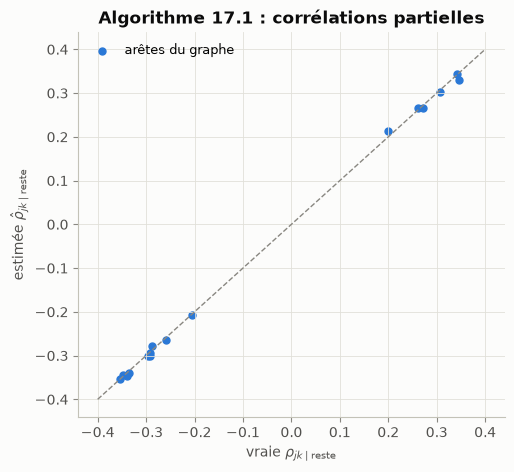

In [5]:
R_est = g.partial_correlations(T17)
R_vrai = g.partial_correlations(Theta_vrai)
iu = np.triu_indices(p, 1)
sur_arete = A_fig[iu]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(R_vrai[iu][sur_arete], R_est[iu][sur_arete], color=BLUE, label="arêtes du graphe")
ax.plot([-0.4, 0.4], [-0.4, 0.4], color=GRAY, ls="--", lw=1)
ax.set(title="Algorithme 17.1 : corrélations partielles", xlabel=r"vraie $\rho_{jk\mid\mathrm{reste}}$",
       ylabel=r"estimée $\hat\rho_{jk\mid\mathrm{reste}}$")
ax.legend()
plt.show()

**Pourquoi coupler les régressions ?** Une approche naïve ferait $p$ régressions
séparées de chaque variable sur ses voisins **avec $S_{11}$** (au lieu de $W_{11}$), puis
symétriserait. Comparons les log-vraisemblances profilées $\ell = \log\det\Theta - \operatorname{tr}(S\Theta)$.

In [6]:
T_naif = np.zeros((p, p))
for j in range(p):
    vois = np.flatnonzero(A_fig[j])
    b = np.linalg.solve(Sc[np.ix_(vois, vois)], Sc[vois, j])
    t22 = 1.0 / (Sc[j, j] - Sc[vois, j] @ b)
    T_naif[j, j] = t22
    T_naif[vois, j] = -b * t22
T_naif = (T_naif + T_naif.T) / 2
for nom_, T_ in [("régressions séparées (naïf)", T_naif), ("algorithme 17.1", T17),
                 ("graphe complet (S^-1)", np.linalg.inv(Sc))]:
    print("%-28s : l = %.5f" % (nom_, g.gaussian_loglik(T_, Sc)))

régressions séparées (naïf)  : l = -8.61960
algorithme 17.1              : l = -8.61949
graphe complet (S^-1)        : l = -8.61328


L'algorithme 17.1 atteint bien le maximum contraint, supérieur à l'approche naïve. Le
graphe complet a une vraisemblance un peu plus grande (il a 39 paramètres de plus).

**Test du rapport de vraisemblance.** La log-vraisemblance totale vaut $\tfrac N2\ell$ à une
constante près, donc la statistique de test $2(\log L_{\text{complet}} - \log L_{\text{graphe}}) = N(\ell_{\text{complet}} - \ell_{\text{graphe}})$
suit approximativement une loi du $\chi^2$ à $55 - 16 = 39$ degrés de liberté si le graphe
est correct. Testons aussi un graphe **faux** (une vraie arête retirée).

In [7]:
def test_graphe(A_test):
    _, T_ = g.fit_known_graph(Sc, A_test)
    stat = N * (g.gaussian_loglik(np.linalg.inv(Sc), Sc) - g.gaussian_loglik(T_, Sc))
    ddl = p * (p - 1) // 2 - A_test.sum() // 2
    return stat, ddl, stats.chi2.sf(stat, ddl)


A_faux = A_fig.copy()
j0, k0 = noms.index("PIP2"), noms.index("Akt")
A_faux[j0, k0] = A_faux[k0, j0] = False
for nom_, A_ in [("graphe de la figure 17.1", A_fig), ("sans l'arête PIP2-Akt", A_faux)]:
    st, ddl, pv = test_graphe(A_)
    print("%-26s : statistique = %8.1f, ddl = %d, p-valeur = %.3g" % (nom_, st, ddl, pv))

graphe de la figure 17.1   : statistique =     46.3, ddl = 39, p-valeur = 0.196
sans l'arête PIP2-Akt      : statistique =   1042.4, ddl = 40, p-valeur = 1.58e-192


Le vrai graphe n'est pas rejeté ; retirer une vraie arête est massivement rejeté.

> **À retenir.** L'algorithme 17.1 résout exactement le maximum de vraisemblance à
> graphe imposé ; ses $p$ régressions sont couplées par la covariance courante $W$. La
> solution reproduit les covariances observées sur les arêtes et la diagonale (complétion
> définie positive de $S$).

## Exercice 17.8 : Lasso par descente de coordonnées et graphical lasso

**Énoncé.** (a) Programmer le lasso par descente de coordonnées (17.26) et comparer
aux résultats de LARS ou d'un autre solveur convexe. (b) À l'aide de (a), programmer le
graphical lasso (algorithme 17.2), l'appliquer aux données de cytométrie, faire varier
le paramètre de régularisation et examiner les réseaux obtenus.

### (a) Lasso par descente de coordonnées

**Rappel.** Le lasso $\min_\beta \frac{1}{2N}\|y - Z\beta\|^2 + \lambda\|\beta\|_1$ (variables centrées)
s'écrit $\min_\beta \frac12\beta^TV\beta - s^T\beta + \lambda\|\beta\|_1$ avec $V = Z^TZ/N$ et
$s = Z^Ty/N$. En minimisant en $\beta_j$ seule (lasso à une variable, voir le cours 1) :

$$
\beta_j \leftarrow \mathcal S\Big(s_j - \sum_{k\neq j}V_{kj}\beta_k,\;\lambda\Big)\Big/V_{jj}.
$$

Chaque mise à jour fait décroître le critère ; comme il est convexe, le cycle converge vers
le minimum.

In [8]:
def lasso_dc(V, s, lam, beta=None, tol=1e-12, max_cycles=10000):
    """Lasso (forme covariance) par descente de coordonnées cyclique."""
    q = len(s)
    beta = np.zeros(q) if beta is None else beta.copy()
    for _ in range(max_cycles):
        ecart = 0.0
        for j in range(q):
            r = s[j] - V[j] @ beta + V[j, j] * beta[j]     # résidu partiel
            nouveau = g.soft_threshold(r, lam) / V[j, j]
            ecart = max(ecart, abs(nouveau - beta[j]))
            beta[j] = nouveau
        if ecart < tol:
            break
    return beta

Comparaison au chemin LARS-lasso de `sklearn.linear_model.lars_path` (solveur exact
par morceaux linéaires) sur les données de prostate standardisées (chapitre 3). Dans
`lars_path`, les valeurs `alphas` sont exactement nos $\lambda$ (critère normalisé par $N$).

In [9]:
from sklearn.linear_model import lars_path
from esl import datasets

pro = datasets.load_prostate()
cols = ["lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45"]
Zp = pro[cols].to_numpy(dtype=float)
Zp = (Zp - Zp.mean(0)) / Zp.std(0)
yp = pro["lpsa"].to_numpy(dtype=float)
yp = yp - yp.mean()
Np = len(yp)
alphas, _, coefs_lars = lars_path(Zp, yp, method="lasso")
V, s = Zp.T @ Zp / Np, Zp.T @ yp / Np
coefs_dc = np.array([lasso_dc(V, s, a) for a in alphas]).T
print("écart max DC / LARS sur les %d nœuds du chemin : %.1e" % (len(alphas), np.abs(coefs_dc - coefs_lars).max()))

écart max DC / LARS sur les 9 nœuds du chemin : 1.2e-12


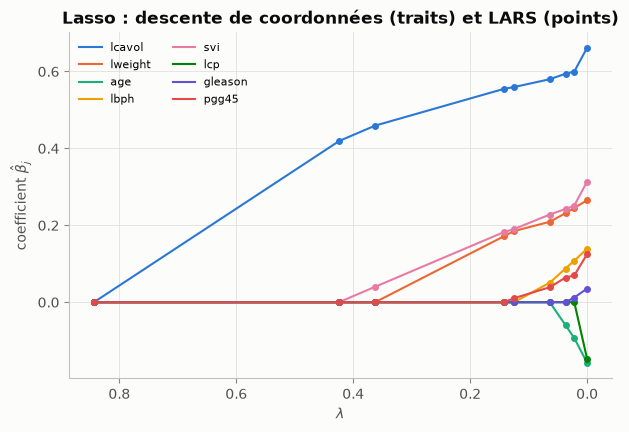

In [10]:
lam_grille = np.linspace(alphas.max(), 0, 200)
chemin_dc = np.array([lasso_dc(V, s, a) for a in lam_grille])
fig, ax = plt.subplots(figsize=(7, 4.5))
for j in range(len(cols)):
    ax.plot(lam_grille, chemin_dc[:, j], color=COLORS[j], lw=1.5, label=cols[j])
    ax.plot(alphas, coefs_lars[j], "o", color=COLORS[j], ms=4)
ax.invert_xaxis()
ax.set(title="Lasso : descente de coordonnées (traits) et LARS (points)",
       xlabel=r"$\lambda$", ylabel=r"coefficient $\hat\beta_j$")
ax.legend(ncol=2, fontsize=8)
plt.show()

Les deux méthodes coïncident en chaque nœud du chemin LARS (à $10^{-10}$ près).

### (b) Graphical lasso

On remplace l'étape (b) de l'algorithme 17.1 par le lasso modifié
$W_{11}\beta - s_{12} + \lambda\operatorname{Sign}(\beta) = 0$ résolu par `lasso_dc`, avec
$V = W_{11}$ et $s = s_{12}$, et on initialise $W = S + \lambda I$.